In [8]:
from google.colab import files
import os

uploaded = files.upload()
DATA_PATH = list(uploaded.keys())[0]
print("Using file:", DATA_PATH)

Saving customer_churn_cleaned (5).csv to customer_churn_cleaned (5).csv
Using file: customer_churn_cleaned (5).csv


In [9]:
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             classification_report, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

MODEL_PATH = "churn_model.joblib"
TARGET = "Churn"
RANDOM_STATE = 42
TEST_SIZE = 0.2

NUMERIC_COLUMNS = [
    "Age", "Tenure", "Monthly_Charges", "Total_Charges", "Support_Calls",
    "Complaints", "Internet_Usage_GB", "Avg_Session_Minutes", "Discount",
    "Satisfaction_Score", "Customer_Service_Rating", "Auto_Payment",
    "Calls_Per_Month", "Charges_Per_Month",
]
CATEGORY_COLUMNS = [
    "Gender", "State", "Contract_Type", "Subscription_Plan",
    "Payment_Method", "Login_Frequency", "Device_Type", "Referral_Source",
]


In [10]:

MISSING_WORDS = {"-", "unknown", "not available", "nan", "none", ""}



def get_number(value):
    """Pull the first number out of text. Handles '₹1,395', 'Rs. 780', '0.6K', '38 years'."""
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    if text in MISSING_WORDS:
        return np.nan
    text = text.replace(",", "")
    match = re.search(r"\d+\.?\d*", text)
    if match is None:
        return np.nan
    number = float(match.group())
    if re.search(r"\d\s*k\b", text):
        number *= 1000
    return number


def clean_text(value):
    """Lower-case text; return NaN for 'Unknown', '-', 'Not Available'."""
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    return np.nan if text in MISSING_WORDS else text


def map_values(series, mapping):
    """Clean text, then map different spellings to ONE standard label."""
    return series.apply(clean_text).map(mapping)


def clean_tenure(value):
    """Return tenure in MONTHS ('2 years' -> 24, '8M' -> 8)."""
    number = get_number(value)
    if pd.notna(number) and "year" in str(value).lower():
        number *= 12
    return number


def clean_session(value):
    """Return session length in MINUTES ('0.5 hours' -> 30)."""
    number = get_number(value)
    if pd.notna(number) and "hour" in str(value).lower():
        number *= 60
    return number


def clean_discount(value):
    """Return discount as a percentage ('0.05' -> 5, '10%' -> 10, 'No Discount' -> 0)."""
    if pd.notna(value) and str(value).strip().lower() == "no discount":
        return 0.0
    number = get_number(value)
    if pd.notna(number) and 0 < number < 1:   # 0.05 means 5%
        number *= 100
    return number


def clean_complaints(value):
    if pd.notna(value) and str(value).strip().lower() == "no complaints":
        return 0.0
    return get_number(value)


def clean_satisfaction(value):
    """Score 1-5. '03-May' is a broken '3' (Excel turned it into a date)."""
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    words = {"poor": 2, "average": 3, "good": 4, "very satisfied": 5}
    if text in words:
        return words[text]
    if text.endswith("-may"):
        return float(text.split("-")[0])
    return get_number(text)


def clean_service_rating(value):
    """Rating 1-5 from '4', '4 stars' or words like 'Poor' / 'Excellent'."""
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    words = {"poor": 2, "average": 3, "good": 4, "excellent": 5}
    if text in words:
        return words[text]
    return get_number(text)


GENDER = {"m": "Male", "male": "Male", "f": "Female", "female": "Female"}
CONTRACT = {"monthly": "Monthly", "month-to-month": "Monthly", "m2m": "Monthly",
            "annual": "Annual", "yearly": "Annual", "two-year": "Two-Year"}
PLAN = {"basic": "Basic", "basic plan": "Basic", "premium": "Premium",
        "premium plan": "Premium", "pro": "Pro", "pro plan": "Pro"}
PAYMENT = {"bank transfer": "Bank Transfer", "upi": "UPI",
           "debit card": "Debit Card", "debit_card": "Debit Card",
           "credit card": "Credit Card", "creditcard": "Credit Card", "cc": "Credit Card"}
YES_NO = {"yes": 1, "y": 1, "1": 1, "no": 0, "n": 0, "0": 0}
LOGIN = {"daily": "Daily", "weekly": "Weekly", "2-3 times/week": "2-3 times/week",
         "monthly": "Monthly", "rarely": "Rarely"}
DEVICE = {"ios": "iOS", "iphone": "iOS", "android": "Android", "android phone": "Android",
          "mobile": "Mobile", "laptop": "Laptop"}
REFERRAL = {"website": "Website", "google": "Google", "google search": "Google",
            "friend": "Friend", "friend referral": "Friend",
            "social media": "Social Media", "advertisement": "Advertisement"}
STATE = {"tamil nadu": "Tamil Nadu", "tn": "Tamil Nadu", "delhi": "Delhi", "dl": "Delhi",
         "kerala": "Kerala", "kl": "Kerala", "gujarat": "Gujarat", "gj": "Gujarat",
         "maharashtra": "Maharashtra", "mh": "Maharashtra", "karnataka": "Karnataka",
         "ka": "Karnataka", "andhra pradesh": "Andhra Pradesh", "ap": "Andhra Pradesh",
         "telangana": "Telangana"}
CHURN = {"yes": 1, "y": 1, "1": 1, "churned": 1, "no": 0, "n": 0, "0": 0, "active": 0}



def clean_data(df):
    """Clean the raw dataframe. Works for training data AND new data (no Churn column)."""
    df = df.copy()

    df = df.drop_duplicates(subset="Customer_ID", keep="first")


    df["Age"] = df["Age"].apply(get_number)
    df["Tenure"] = df["Tenure"].apply(clean_tenure)
    df["Monthly_Charges"] = df["Monthly_Charges"].apply(get_number)
    df["Total_Charges"] = df["Total_Charges"].apply(get_number)
    df["Support_Calls"] = df["Support_Calls"].apply(get_number)
    df["Complaints"] = df["Complaints"].apply(clean_complaints)
    df["Internet_Usage_GB"] = df["Internet_Usage_GB"].apply(get_number)
    df["Avg_Session_Minutes"] = df["Avg_Session_Minutes"].apply(clean_session)
    df["Discount"] = df["Discount"].apply(clean_discount)
    df["Satisfaction_Score"] = df["Satisfaction_Score"].apply(clean_satisfaction)
    df["Customer_Service_Rating"] = df["Customer_Service_Rating"].apply(clean_service_rating)

    df["Gender"] = map_values(df["Gender"], GENDER)
    df["State"] = map_values(df["State"], STATE)
    df["Contract_Type"] = map_values(df["Contract_Type"], CONTRACT)
    df["Subscription_Plan"] = map_values(df["Subscription_Plan"], PLAN)
    df["Payment_Method"] = map_values(df["Payment_Method"], PAYMENT)
    df["Auto_Payment"] = map_values(df["Auto_Payment"], YES_NO)
    df["Login_Frequency"] = map_values(df["Login_Frequency"], LOGIN)
    df["Device_Type"] = map_values(df["Device_Type"], DEVICE)
    df["Referral_Source"] = map_values(df["Referral_Source"], REFERRAL)

    df.loc[(df["Age"] < 18) | (df["Age"] > 100), "Age"] = np.nan
    for col in ["Tenure", "Monthly_Charges", "Total_Charges", "Support_Calls",
                "Complaints", "Internet_Usage_GB", "Avg_Session_Minutes"]:
        df.loc[df[col] < 0, col] = np.nan

    df["Calls_Per_Month"] = df["Support_Calls"] / (df["Tenure"] + 1)
    df["Charges_Per_Month"] = df["Total_Charges"] / (df["Tenure"] + 1)

    if TARGET in df.columns:
        df[TARGET] = map_values(df[TARGET], CHURN)
        df = df.dropna(subset=[TARGET])
        df[TARGET] = df[TARGET].astype(int)

    return df.reset_index(drop=True)

In [11]:
raw = pd.read_csv(DATA_PATH)
df = clean_data(raw)

print(f"Rows: {len(raw)} -> {len(df)} after removing duplicates")
print(f"Churn rate: {df[TARGET].mean():.1%}")
df.head()

Rows: 1100 -> 1069 after removing duplicates
Churn rate: 20.5%


,Customer_ID,Customer_Name,Gender,Age,City,State,Signup_Date,Last_Login,Tenure,Contract_Type,...,Customer_Service_Rating,Device_Type,Referral_Source,Churn,Churn_Date,Churn_Reason,Customer_Notes,Data_Source,Calls_Per_Month,Charges_Per_Month
0,cus_0249,ananya rao,Male,38.0,warangal,Telangana,Jul 11 2026,08/27/2026,1.0,Monthly,...,2.0,Mobile,Friend,0,NaN,Not churned,NaN,CRM,NaN,250.000000
1,cus_0106,Riya Kapoor,Male,49.0,Tirupati,Andhra Pradesh,Aug 26 2024,08/22/2026,24.0,Two-Year,...,4.0,Android,Friend,0,NaN,Not churned,customer happy with service,mobile app,0.040000,424.000000
2,cus_0197,SURESH BABU,Female,26.0,NaN,Delhi,21-07-2026,27-08-2026,1.0,Monthly,...,5.0,Android,Google,0,NaN,NaN,moved to competitor,Mobile App,3.000000,207.500000
3,CUS-0891,Sneha Patel,Female,55.0,delhi,NaN,16-Apr-26,30-Aug-26,12.0,Monthly,...,NaN,iOS,Google,0,NaN,NaN,NaN,API,0.153846,392.307692
4,CUS-0333,amit shah,Male,39.0,Not Available,Telangana,Jul 14 2026,08/27/2026,12.0,Monthly,...,2.0,Android,Google,0,NaN,NaN,customer happy with service,Import,0.000000,92.461538


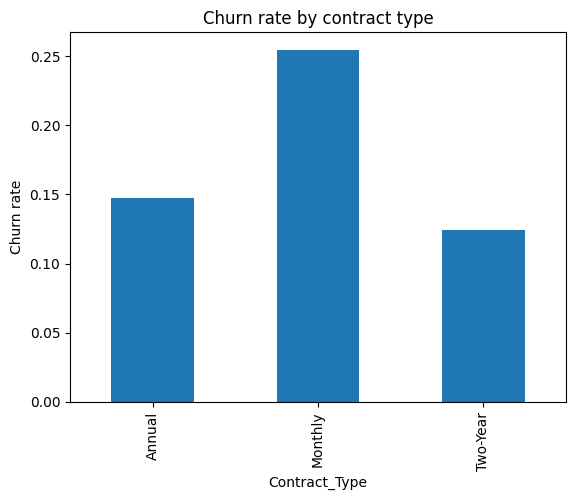

In [12]:
df.groupby("Contract_Type")[TARGET].mean().plot(kind="bar", title="Churn rate by contract type")
plt.ylabel("Churn rate")
plt.show()

In [13]:
X = df[NUMERIC_COLUMNS + CATEGORY_COLUMNS]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
print("Train:", len(X_train), "| Test:", len(X_test))


def build_preprocessor():
    """Numbers: fill missing with median + scale. Categories: fill missing + one-hot."""
    numeric_steps = Pipeline([
        ("fill_missing", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    category_steps = Pipeline([
        ("fill_missing", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("numbers", numeric_steps, NUMERIC_COLUMNS),
        ("categories", category_steps, CATEGORY_COLUMNS),
    ])

Train: 855 | Test: 214


In [14]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                            random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

def make_pipeline(model):
    return Pipeline([("prep", build_preprocessor()), ("model", model)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = {}
for name, model in models.items():
    result = cross_val_score(make_pipeline(model), X_train, y_train, cv=cv, scoring="roc_auc")
    scores[name] = result.mean()
    print(f"{name:<22} ROC-AUC = {result.mean():.3f} (+/- {result.std():.3f})")

best_name = max(scores, key=scores.get)
print("\nBest model:", best_name)

Logistic Regression    ROC-AUC = 0.547 (+/- 0.073)
Random Forest          ROC-AUC = 0.567 (+/- 0.050)
Gradient Boosting      ROC-AUC = 0.537 (+/- 0.039)

Best model: Random Forest


In [15]:
grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {"model__max_depth": [4, 8, None], "model__min_samples_leaf": [1, 5, 10]},
    "Gradient Boosting": {"model__n_estimators": [100, 200],
                          "model__learning_rate": [0.05, 0.1],
                          "model__max_depth": [2, 3]},
}
search = GridSearchCV(make_pipeline(models[best_name]), grids[best_name],
                      cv=cv, scoring="roc_auc", n_jobs=-1)
search.fit(X_train, y_train)

final_model = search.best_estimator_
print("Best settings:", search.best_params_)
print(f"Tuned CV ROC-AUC = {search.best_score_:.3f}")

Best settings: {'model__max_depth': None, 'model__min_samples_leaf': 10}
Tuned CV ROC-AUC = 0.571


Accuracy  : 0.757
Precision : 0.278
Recall    : 0.114
F1-score  : 0.161
ROC-AUC   : 0.525

              precision    recall  f1-score   support

      Stayed       0.80      0.92      0.86       170
     Churned       0.28      0.11      0.16        44

    accuracy                           0.76       214
   macro avg       0.54      0.52      0.51       214
weighted avg       0.69      0.76      0.71       214



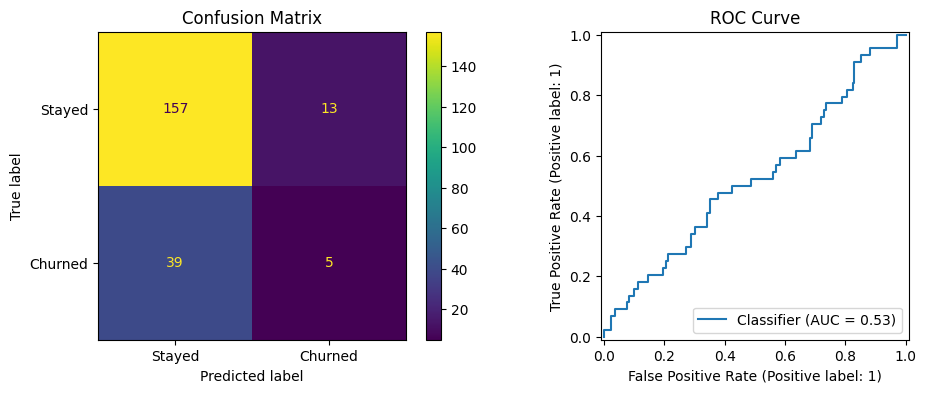

In [16]:
pred = final_model.predict(X_test)
prob = final_model.predict_proba(X_test)[:, 1]

print(f"Accuracy  : {accuracy_score(y_test, pred):.3f}")
print(f"Precision : {precision_score(y_test, pred, zero_division=0):.3f}")
print(f"Recall    : {recall_score(y_test, pred):.3f}")
print(f"F1-score  : {f1_score(y_test, pred):.3f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, prob):.3f}\n")
print(classification_report(y_test, pred, target_names=["Stayed", "Churned"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Stayed", "Churned"], ax=axes[0])
axes[0].set_title("Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, prob, ax=axes[1])
axes[1].set_title("ROC Curve")
plt.show()

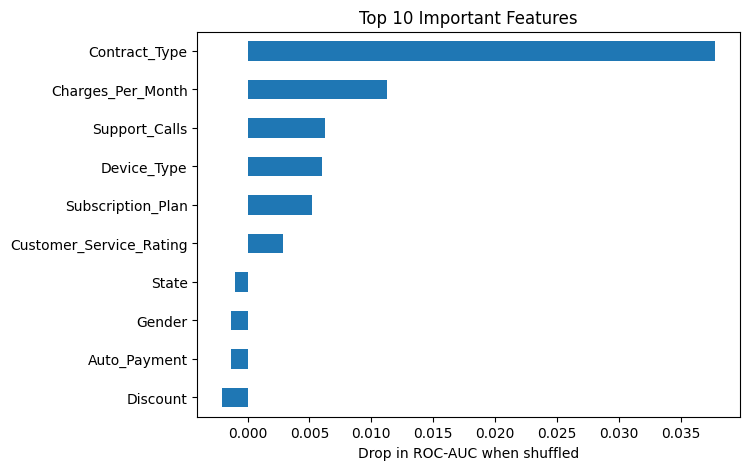

In [17]:
result = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                                n_repeats=10, random_state=RANDOM_STATE)
importance = pd.Series(result.importances_mean, index=X_test.columns).sort_values(ascending=False)

importance.head(10).iloc[::-1].plot(kind="barh", figsize=(7, 5), title="Top 10 Important Features")
plt.xlabel("Drop in ROC-AUC when shuffled")
plt.show()

In [25]:
top10_features = [
    "Contract_Type",
    "Charges_Per_Month",
    "Support_Calls",
    "Device_Type",
    "Subscription_Plan",
    "Customer_Service_Rating",
    "State",
    "Gender",
    "Auto_Payment",
    "Discount"
]

X_train_10 = X_train[top10_features]
X_test_10 = X_test[top10_features]

print("Selected Features:", len(top10_features))
print("Training Shape:", X_train_10.shape)
print("Testing Shape:", X_test_10.shape)

Selected Features: 10
Training Shape: (855, 10)
Testing Shape: (214, 10)


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

num_cols = X_train_10.select_dtypes(include="number").columns
cat_cols = X_train_10.select_dtypes(exclude="number").columns

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

print("Preprocessing completed!")

Preprocessing completed!


In [27]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone

top10_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", clone(final_model.named_steps["model"]))
])

top10_model.fit(X_train_10, y_train)

print("Model training completed!")

Model training completed!


In [28]:
y_pred = top10_model.predict(X_test_10)

print("Model testing completed!")
print("Actual:", list(y_test[:10]))
print("Predicted:", list(y_pred[:10]))

Model testing completed!
Actual: [0, 0, 0, 0, 0, 0, 0, 0, 1, 0]
Predicted: [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]


In [29]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Top 10 Features Model Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Active", "Churned"],
    zero_division=0
))

Top 10 Features Model Accuracy: 65.42 %

Classification Report:
              precision    recall  f1-score   support

      Active       0.81      0.74      0.77       170
     Churned       0.25      0.34      0.29        44

    accuracy                           0.65       214
   macro avg       0.53      0.54      0.53       214
weighted avg       0.70      0.65      0.67       214

